In [1]:
import os
import glob
import random
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import pyttsx3

# 1. Danh sách 10 nhãn theo đúng thứ tự lúc huấn luyện trên Google Colab
CLASS_NAMES = [
    '1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000', 'khong_phai_tien'
]

# Tên hiển thị tiếng Việt và câu đọc loa
LABEL_MAP = {
    '1000': '1.000 VNĐ',
    '2000': '2.000 VNĐ',
    '5000': '5.000 VNĐ',
    '10000': '10.000 VNĐ',
    '20000': '20.000 VNĐ',
    '50000': '50.000 VNĐ',
    '100000': '100.000 VNĐ',
    '200000': '200.000 VNĐ',
    '500000': '500.000 VNĐ',
    'khong_phai_tien': 'Không phải tiền'
}

# 2. Khởi tạo và nạp mô hình MobileNetV3
device = torch.device('cpu')
model = models.mobilenet_v3_small(weights=None)
model.classifier[3] = torch.nn.Linear(1024, len(CLASS_NAMES))

model_path = os.path.join('..', 'models', 'best_mobilenetv3.pth')
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

# 3. Tiền xử lý ảnh chuẩn
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print('✅ Đã nạp mô hình thành công và sẵn sàng kiểm tra!')

✅ Đã nạp mô hình thành công và sẵn sàng kiểm tra!


📊 Tổng số ảnh test: 813 | Accuracy: 98.03% (797/813)
🎯 Độ tin cậy TB khi ĐÚNG: 90.55%
⚠️ Độ tin cậy TB khi SAI : 50.39%
🔎 Số ảnh có độ tin cậy < 80%: 73/813

Lớp              | Số ảnh | Precision |   Recall | F1-Score |  Conf TB
------------------------------------------------------------------------
1000             |     68 |   100.00% |  100.00% |  100.00% |   90.88%
10000            |     81 |    96.34% |   97.53% |   96.93% |   92.00%
100000           |     98 |    97.96% |   97.96% |   97.96% |   91.34%
2000             |     60 |   100.00% |  100.00% |  100.00% |   93.86%
20000            |     96 |    94.90% |   96.88% |   95.88% |   87.25%
200000           |     94 |    98.92% |   97.87% |   98.40% |   91.53%
5000             |     68 |    98.55% |  100.00% |   99.27% |   92.35%
50000            |     87 |    98.86% |  100.00% |   99.43% |   91.58%
500000           |     90 |    97.75% |   96.67% |   97.21% |   89.94%
khong_phai_tien  |     71 |    98.53% |   94.37% |   96.40%

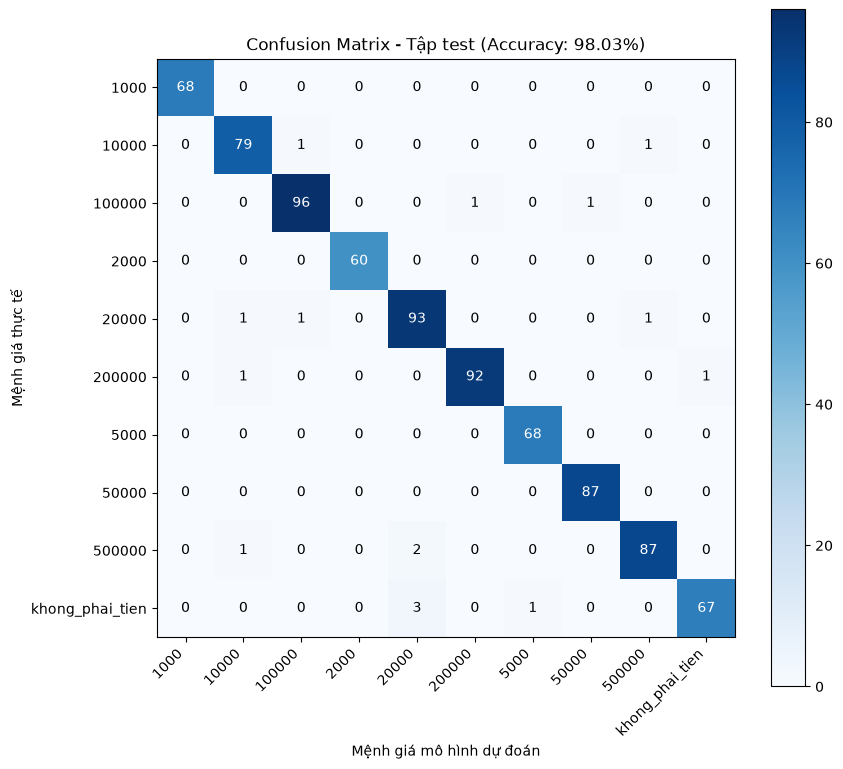

In [2]:
import numpy as np

# 1. Quét và dự đoán toàn bộ ảnh trong data_test
y_true, y_pred, confs, wrong_cases = [], [], [], []
valid_exts = ('.jpg', '.jpeg', '.png', '.webp')

for idx, cls in enumerate(CLASS_NAMES):
    folder = os.path.join('..\\data\\data_v1\\test', cls)
    if not os.path.isdir(folder):
        continue
    for fname in sorted(os.listdir(folder)):
        if not fname.lower().endswith(valid_exts):
            continue
        path = os.path.join(folder, fname)
        img = Image.open(path).convert('RGB')
        x = transform(img).unsqueeze(0).to(device)
        with torch.no_grad():
            prob = torch.nn.functional.softmax(model(x)[0], dim=0)
            conf, pred = torch.max(prob, 0)
        y_true.append(idx)
        y_pred.append(pred.item())
        confs.append(conf.item())
        if pred.item() != idx:
            wrong_cases.append((path, cls, CLASS_NAMES[pred.item()], conf.item() * 100))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
confs = np.array(confs)

# 2. Tổng quan độ chính xác & phân bố độ tin cậy
acc = (y_true == y_pred).mean() * 100
print(f"📊 Tổng số ảnh test: {len(y_true)} | Accuracy: {acc:.2f}% ({(y_true==y_pred).sum()}/{len(y_true)})")
print(f"🎯 Độ tin cậy TB khi ĐÚNG: {confs[y_true==y_pred].mean()*100:.2f}%")
if (y_true != y_pred).any():
    print(f"⚠️ Độ tin cậy TB khi SAI : {confs[y_true!=y_pred].mean()*100:.2f}%")
print(f"🔎 Số ảnh có độ tin cậy < 80%: {(confs < 0.8).sum()}/{len(y_true)}\n")

# 3. Bảng chi tiết từng mệnh giá
print(f"{'Lớp':16s} | {'Số ảnh':>6s} | {'Precision':>9s} | {'Recall':>8s} | {'F1-Score':>8s} | {'Conf TB':>8s}")
print("-" * 72)
cm = np.zeros((len(CLASS_NAMES), len(CLASS_NAMES)), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

for i, cls in enumerate(CLASS_NAMES):
    tp = cm[i, i]
    fp = cm[:, i].sum() - tp
    fn = cm[i, :].sum() - tp
    n = cm[i, :].sum()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    mc   = confs[y_true == i].mean() * 100 if n else 0.0
    print(f"{cls:16s} | {n:6d} | {prec*100:8.2f}% | {rec*100:7.2f}% | {f1*100:7.2f}% | {mc:7.2f}%")

# 4. Vẽ Confusion Matrix trên tập Test
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_yticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Mệnh giá mô hình dự đoán')
ax.set_ylabel('Mệnh giá thực tế')
ax.set_title(f'Confusion Matrix - Tập test (Accuracy: {acc:.2f}%)')

thresh = cm.max() / 2.0
for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='white' if cm[i, j] > thresh else 'black')
plt.tight_layout()
plt.show()

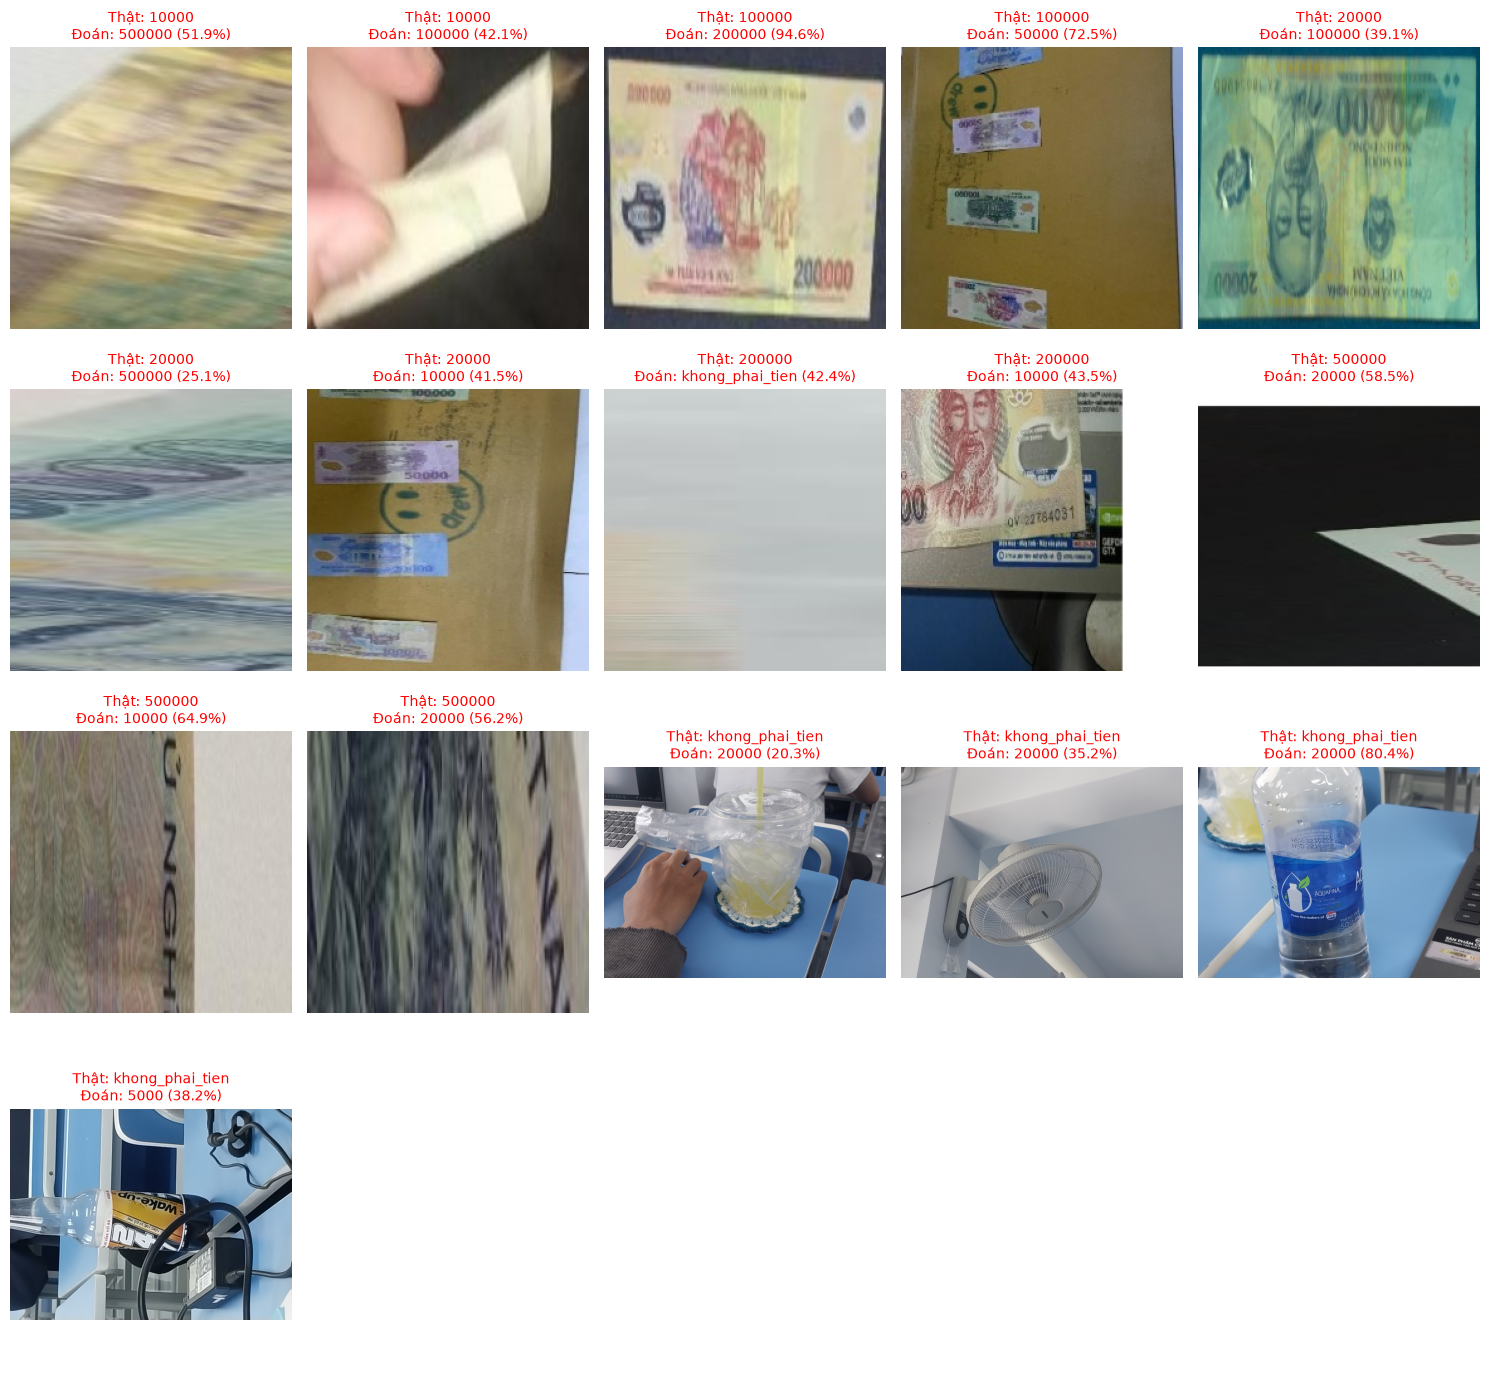

In [3]:
# Hiển thị toàn bộ các ảnh bị dự đoán sai
if not wrong_cases:
    print("🎉 Không có ảnh nào đoán sai!")
else:
    cols = 5
    rows = (len(wrong_cases) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 3.5 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (path, true_lbl, pred_lbl, conf) in zip(axes, wrong_cases):
        ax.imshow(Image.open(path).convert('RGB'))
        ax.set_title(f"Thật: {true_lbl}\nĐoán: {pred_lbl} ({conf:.1f}%)", color='red', fontsize=10)
        ax.axis('off')
    for ax in axes[len(wrong_cases):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

In [4]:
from torchvision.transforms import functional as TF
from PIL import ImageFilter

# Lấy mẫu tối đa 20 ảnh mỗi mệnh giá để stress test nhanh
sample_items = []
for idx, cls in enumerate(CLASS_NAMES):
    folder = os.path.join('..\\data\\data_v1\\test', cls)
    if not os.path.isdir(folder):
        continue
    for f in sorted(os.listdir(folder))[:20]:
        if f.lower().endswith(valid_exts):
            sample_items.append((idx, Image.open(os.path.join(folder, f)).convert('RGB').resize((224, 224))))

scenarios = {
    'Ảnh gốc'           : lambda im: im,
    'Thiếu sáng (0.5x)' : lambda im: TF.adjust_brightness(im, 0.5),
    'Chói sáng (1.5x)'  : lambda im: TF.adjust_brightness(im, 1.5),
    'Xoay +15 độ'       : lambda im: im.rotate(15),
    'Xoay 90 độ'        : lambda im: im.rotate(90),
    'Lật gương ngang'   : lambda im: im.transpose(Image.FLIP_LEFT_RIGHT),
    'Làm mờ (r=2)'      : lambda im: im.filter(ImageFilter.GaussianBlur(radius=2)),
    'Cắt mất 25% viền'  : lambda im: im.crop((28, 28, 196, 196)),
}

print(f"{'Kịch bản kiểm thử':20s} | {'Accuracy':>9s} | {'Độ tin cậy TB':>13s}")
print("-" * 50)
for name, aug in scenarios.items():
    ok, cs = 0, []
    with torch.no_grad():
        for idx, im in sample_items:
            x = transform(aug(im)).unsqueeze(0).to(device)
            prob = torch.nn.functional.softmax(model(x)[0], dim=0)
            c, p = torch.max(prob, 0)
            ok += int(p.item() == idx)
            cs.append(c.item() * 100)
    print(f"{name:20s} | {ok/len(sample_items)*100:8.2f}% | {np.mean(cs):12.2f}%")

Kịch bản kiểm thử    |  Accuracy | Độ tin cậy TB
--------------------------------------------------
Ảnh gốc              |    97.00% |        88.20%
Thiếu sáng (0.5x)    |    99.00% |        81.87%
Chói sáng (1.5x)     |    85.00% |        73.69%
Xoay +15 độ          |    96.50% |        86.91%
Xoay 90 độ           |    97.00% |        87.89%
Lật gương ngang      |    97.00% |        88.06%
Làm mờ (r=2)         |    95.00% |        85.54%
Cắt mất 25% viền     |    95.50% |        81.55%
